# Part 2: Data Quality and Exploratory Data Analysis

## 1. Load and Inspect the Dataset

In [2]:
import pandas as pd

file_name = "student-mat.xlsx"

excel_file = pd.ExcelFile(file_name)

df_raw = pd.read_excel(excel_file, sheet_name=0)

print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())

Rows: 395
Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Data source: UCI Machine Learning Repository, Student Performance.

https://archive.ics.uci.edu/dataset/320/student+performance

File analysed: student-mat.xlsx

Subject: Mathematics

## 2. Data Quality Checks

### 2.1 Data Types and Non-Missing Counts

In [5]:
df_raw.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### 2.2 Missing Values

In [7]:
missing_counts = df_raw.isna().sum()

display(missing_counts)

print("Total missing values:", missing_counts.sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


All 33 columns contain 395 non-null values.
No missing values were detected using pandas isna().
Therefore, no missing-value imputation was performed.

### 2.3 Duplicate Records

In [10]:
duplicate_count = df_raw.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


No exact duplicate rows were found across all 33 columns.
No records were removed during this check.

### 2.4 Numerical Range Checks

In [13]:
numeric_summary = df_raw.describe()

display(numeric_summary.loc[["min", "max"]])

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
min,15.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0,0.0,0.0
max,22.0,4.0,4.0,4.0,4.0,3.0,5.0,5.0,5.0,5.0,5.0,5.0,75.0,19.0,19.0,20.0


The inspected minimum and maximum values fall within the documented
bounds for age, parental education, travel time, study time, rating-scale
variables, absences, and grades.

The coding of failures requires further clarification.

### 2.5 Categorical Value Checks

In [16]:
text_columns = df_raw.select_dtypes(include="object").columns

for column in text_columns:
    print(column, ":", df_raw[column].unique())

school : ['GP' 'MS']
sex : ['F' 'M']
address : ['U' 'R']
famsize : ['GT3' 'LE3']
Pstatus : ['A' 'T']
Mjob : ['at_home' 'health' 'other' 'services' 'teacher']
Fjob : ['teacher' 'other' 'services' 'health' 'at_home']
reason : ['course' 'other' 'home' 'reputation']
guardian : ['mother' 'father' 'other']
schoolsup : ['yes' 'no']
famsup : ['no' 'yes']
paid : ['no' 'yes']
activities : ['no' 'yes']
nursery : ['yes' 'no']
higher : ['yes' 'no']
internet : ['no' 'yes']
romantic : ['no' 'yes']


All 17 text columns contain categories consistent with the supplied
data dictionary. No unexpected labels or blank text entries were
observed in these columns.

No category labels were modified.

### 2.6 Numeric Category Checks

In [19]:
coded_columns = [
    "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health"
]

for column in coded_columns:
    print(column, ":", sorted(df_raw[column].unique()))

Medu : [0, 1, 2, 3, 4]
Fedu : [0, 1, 2, 3, 4]
traveltime : [1, 2, 3, 4]
studytime : [1, 2, 3, 4]
failures : [0, 1, 2, 3]
famrel : [1, 2, 3, 4, 5]
freetime : [1, 2, 3, 4, 5]
goout : [1, 2, 3, 4, 5]
Dalc : [1, 2, 3, 4, 5]
Walc : [1, 2, 3, 4, 5]
health : [1, 2, 3, 4, 5]


The observed codes for parental education, travel time, study time,
and the 1–5 rating-scale variables match the supplied definitions.

### 2.7 Data Quality Summary

The dataset contains 395 records and 33 columns.

No missing values were detected using pandas isna(), and no exact duplicate rows were
found across all 33 columns.

The inspected numerical ranges were within the supplied bounds, except that the coding of failures requires further clarification.
The text categories and the other numerically coded categories matched the allowed values in the data dictionary. 
No blank text entries were observed in the text columns.

No records or values were changed during these checks. 
The failures variable will be excluded from the subsequent analysis because the study does not use prior academic performance, 
not because the variable was confirmed to be invalid.

## 3. Define the Analysis Dataset
### 3.1 Exclude Prior Academic Performance Variables

In [23]:
excluded_columns = ["G1", "G2", "failures"]

df_analysis = df_raw.drop(columns=excluded_columns).copy()

print("Original dataset:", df_raw.shape)
print("Analysis dataset:", df_analysis.shape)

print("Excluded columns:", excluded_columns)

Original dataset: (395, 33)
Analysis dataset: (395, 30)
Excluded columns: ['G1', 'G2', 'failures']


G1, G2, and failures are excluded from the analysis inputs because
the study aims to identify students at risk of failing without using prior academic performance.

G3 is retained as the final-grade outcome and will be used to define
the pass/fail target. It will not be used as a predictor.

The original dataset is preserved unchanged.

### 3.2 Define the Target Variable

In [26]:
df_analysis["failed"] = (df_analysis["G3"] < 10).astype(int)

display(df_analysis[["G3", "failed"]].head(10))

,G3,failed
0,6,1
1,6,1
2,10,0
3,15,0
4,10,0
5,15,0
6,11,0
7,6,1
8,19,0
9,15,0


A binary target named failed is derived from the final grade, G3.
Students with G3 below 10 are labelled 1 (fail), 
while students with G3 of 10 or above are labelled 0 (pass).

G3 is used only to construct the target and will not be included as a model input.

### 3.3 Target Distribution

In [29]:
target_counts = df_analysis["failed"].value_counts().sort_index()

target_percentages = (df_analysis["failed"].value_counts(normalize=True).sort_index() * 100).round(2)

print("Student counts (0 = pass, 1 = fail):")
print(target_counts)

print("\nPercentages (0 = pass, 1 = fail):")
print(target_percentages)

Student counts (0 = pass, 1 = fail):
failed
0    265
1    130
Name: count, dtype: int64

Percentages (0 = pass, 1 = fail):
failed
0    67.09
1    32.91
Name: proportion, dtype: float64


Count the students in each outcome group and calculate their
percentages. The failed variable is coded as 0 for pass and 1 for fail.

## 4. Exploratory Data Analysis

### 4.1 Pass/Fail Distribution

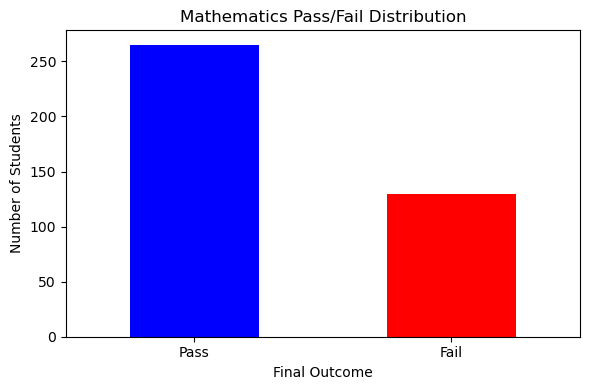

In [32]:
import matplotlib.pyplot as plt

target_counts = (
    df_analysis["failed"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)


target_counts.index = ["Pass", "Fail"]


target_counts.plot.bar(
    color=["blue", "red"],
    rot=0,
    figsize=(6, 4)
)

plt.title("Mathematics Pass/Fail Distribution")
plt.xlabel("Final Outcome")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

Of the 395 students, 265 (67.09%) passed and 130 (32.91%) failed,
using G3 below 10 as the failure criterion.

Passing students outnumber failing students by approximately two to one. 
This describes the outcome distribution but does not explain why students failed.

### 4.2 Study Time and Failure Rate

In [35]:
student_counts = df_analysis.groupby("studytime")["failed"].count()

failure_counts = df_analysis.groupby("studytime")["failed"].sum()

studytime_summary = pd.DataFrame({
    "Students": student_counts,
    "Failed": failure_counts
})

studytime_summary["Failure_Rate_Percent"] = (
    studytime_summary["Failed"] / studytime_summary["Students"] * 100).round(2)

display(studytime_summary)

,Students,Failed,Failure_Rate_Percent
studytime,,,
1,105,37,35.24
2,198,70,35.35
3,65,16,24.62
4,27,7,25.93


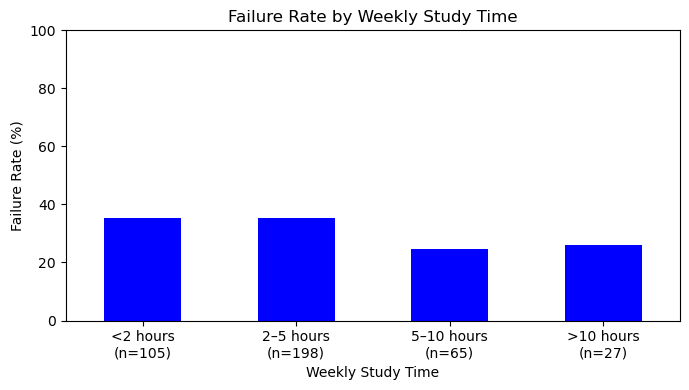

In [36]:
import matplotlib.pyplot as plt

studytime_summary["Failure_Rate_Percent"].plot.bar(
    color="blue",
    rot=0,
    figsize=(7, 4)
)

plt.xticks(
    range(4),
    ["<2 hours\n(n=105)", "2–5 hours\n(n=198)", "5–10 hours\n(n=65)", ">10 hours\n(n=27)"]
)

plt.title("Failure Rate by Weekly Study Time")
plt.xlabel("Weekly Study Time")
plt.ylabel("Failure Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The observed failure rates were 35.24% and 35.35% in the two
lower study-time categories, compared with 24.62% and 25.93%
in the two higher categories.

The pattern was not strictly decreasing across all four categories.
Group sizes also differed, with only 27 students in the highest
study-time category.

These descriptive results do not establish that increasing study
time causes a reduction in failure.

### 4.3 Absences and Final Outcome

In [39]:
absence_summary = (
    df_analysis.groupby("failed")["absences"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

absence_summary.index.name = "failed (0 = pass, 1 = fail)"

display(absence_summary)

,count,median,mean,min,max
"failed (0 = pass, 1 = fail)",,,,,
0,265,4.0,5.19,0,54
1,130,4.0,6.76,0,75


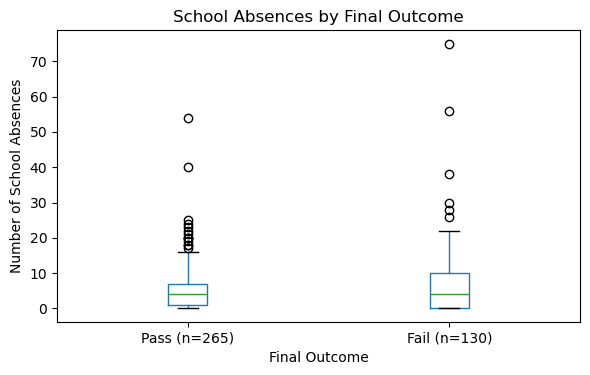

In [40]:
import matplotlib.pyplot as plt

ax = df_analysis.boxplot(
    column="absences",
    by="failed",
    figsize=(6, 4),
    grid=False
)

ax.set_xticks([1, 2])
ax.set_xticklabels(["Pass (n=265)", "Fail (n=130)"])
ax.set_title("School Absences by Final Outcome")
ax.set_xlabel("Final Outcome")
ax.set_ylabel("Number of School Absences")


plt.suptitle("")
plt.tight_layout()
plt.show()

Both groups had a median of 4 absences. The mean was 5.19 for passing students and 6.76 for failing students.

The failing group had a wider interquartile range and a higher maximum observed absence count. 
However, the distributions overlapped substantially.

This comparison does not establish causation or show whether absences improve prediction when combined with other variables.

### 4.4 Mother's Education and Failure Rate

In [43]:
student_counts = df_analysis.groupby("Medu")["failed"].count()

failure_counts = df_analysis.groupby("Medu")["failed"].sum()

medu_summary = pd.DataFrame({
    "Students": student_counts,
    "Failed": failure_counts
})

medu_summary["Failure_Rate_Percent"] = (
    medu_summary["Failed"] / medu_summary["Students"] * 100).round(2)

display(medu_summary)

,Students,Failed,Failure_Rate_Percent
Medu,,,
0,3,1,33.33
1,59,25,42.37
2,103,36,34.95
3,99,35,35.35
4,131,33,25.19


Compare student counts and observed failure rates across
the five categories of mother's education (Medu).

This is a descriptive comparison and does not establish causation.

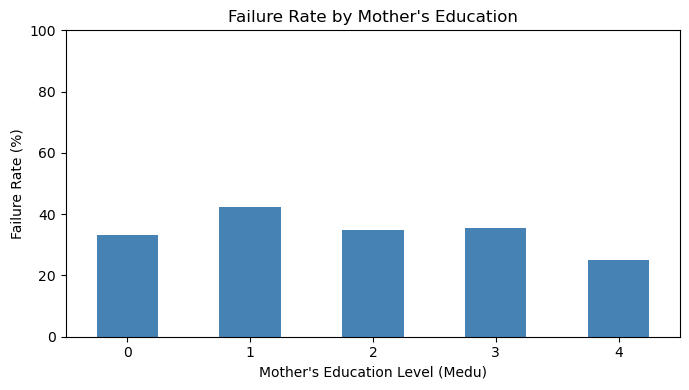

In [45]:
import matplotlib.pyplot as plt

medu_summary["Failure_Rate_Percent"].plot.bar(
    color="steelblue",
    rot=0,
    figsize=(7, 4)
)

plt.title("Failure Rate by Mother's Education")
plt.xlabel("Mother's Education Level (Medu)")
plt.ylabel("Failure Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The observed failure rate was highest for Medu = 1 (25 of 59 students, 42.37%) and lowest for Medu = 4 (33 of 131 students, 25.19%).

The pattern was not strictly decreasing across education levels.
The Medu = 0 group contained only three students, so its percentage should be interpreted cautiously.

These descriptive differences do not establish causation or show whether Medu improves predictive performance when other variables are considered.

### 4.5 EDA Summary and Limitations

Of the 395 students, 265 (67.09%) passed and 130 (32.91%) failed,
using G3 below 10 as the failure criterion.

The absence box plot suggests similar median absence counts between passing and failing students. However, the failing group has a wider interquartile range. 
The distributions overlap considerably, so absences alone do not clearly separate the groups in this plot.
Failure rates differ across mother's education categories.
The observed rate is highest for Medu = 1 (42.37%) and lowest for Medu = 4 (25.19%), but the pattern is not strictly decreasing across education levels. The Medu = 0 group contains only three students, so these percentages should be interpreted with caution.

These results are purely descriptive. 
They neither establish a causal relationship nor demonstrate which variables can improve the model’s predictive performance.
The predictive value of each variable must be evaluated during the modeling phase.
n.